---
title: "TabPFN in the Control Loop"
description: "TabPFN drives a lunar lander and a MuJoCo HalfCheetah by behaviour cloning: expert demonstrations are the context, and one predict call per control step returns the action."
icon: "robot"
cookbookTags:
  - regression
  - multi-target
  - robotics
authors:
  - name: Klemens Flöge
    linkedin: https://www.linkedin.com/in/klemens-fl%C3%B6ge/
---

*Expert demonstrations go into TabPFN's context. At every control step, one `predict` call returns the next action. No training.*

Behaviour cloning learns a policy from an expert's (state, action) pairs. Usually you train a network on those pairs. With TabPFN, the pairs are the context: `fit` stores them, and `predict` maps a new state to an action.

This notebook runs two examples:

1. **Lunar Lander** (Gymnasium Box2D): TabPFN copies Gymnasium's hand-written landing controller. 8 state values in, 2 engine commands out.
2. **HalfCheetah** (MuJoCo): TabPFN copies a pretrained TD3 policy. 17 state values in, 6 joint torques out.

The speed tricks come from [duckpfn](https://github.com/nikikilbertus/duckpfn) by Niki Kilbertus, where TabPFN walks a simulated Microduck robot at 50 Hz.

## Setup

*A GPU runtime, the packages, and access to the TabPFN 3.5 weights.*

1. In Colab, select Runtime > Change runtime type > **T4 GPU**.
2. The TabPFN 3.5 weights are gated. Open the [model page](https://huggingface.co/Prior-Labs/tabpfn_3_5) on Hugging Face and accept the terms.
3. Create a Hugging Face read token under Settings > Access Tokens. In Colab, add it as a secret named `HF_TOKEN` (key icon in the left bar) and switch on notebook access. Outside Colab, set the `HF_TOKEN` environment variable. If neither is set, the notebook asks for the token.

`swig` must be installed first, because the Box2D physics engine builds from source.

In [1]:
%pip install -q swig
%pip install -q "tabpfn==10.2.0" "gymnasium[box2d,mujoco]" stable-baselines3 huggingface_sb3 imageio

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


*Download the TabPFN 3.5 Fast checkpoint. It is the smallest TabPFN 3.5 model and the fastest at prediction time.*

In [2]:
import os
from getpass import getpass

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
from huggingface_hub import hf_hub_download

token = os.environ.get("HF_TOKEN")
if not token:
    try:
        from google.colab import userdata

        token = userdata.get("HF_TOKEN")
    except Exception:  # not in Colab, or no secret with that name
        token = getpass("Hugging Face token: ")

CHECKPOINT = hf_hub_download(
    "Prior-Labs/tabpfn_3_5", "tabpfn-v3.5-fast-20260909.safetensors", local_dir="checkpoints", token=token
)
print(CHECKPOINT)

checkpoints/tabpfn-v3.5-fast-20260909.safetensors


In [3]:
os.environ["MUJOCO_GL"] = "egl"  # MuJoCo renders off-screen on the GPU; set before MuJoCo loads

import time

import gymnasium as gym
import imageio.v2 as imageio
import numpy as np
import torch
from IPython.display import Image, display
from tabpfn import TabPFNRegressor
from tabpfn.constants import ModelVersion

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

cuda Tesla T4


## Make TabPFN fast enough for a control loop

*Three settings keep one prediction in the range of tens of milliseconds.*

- `fit_mode="fit_with_cache"`: TabPFN encodes the context once, in `fit`. Each `predict` call then only processes the new rows.
- `n_estimators=1` with the TabPFN 3.5 Fast checkpoint: one forward pass per call.
- One call for all outputs. `TabPFNRegressor` predicts one number per row, but the robots need 2 or 6 numbers per step. `PooledRegressor` repeats each state once per output and adds an output-id column. One table holds all outputs, so one `predict` call answers all of them. This is the duckpfn trick.

`PooledRegressor` also standardizes each output and records the time of every `predict` call.

In [4]:
class PooledRegressor:
    """Predict k outputs with one TabPFN table: each row gets an output-id column."""

    def __init__(self):
        self.model = TabPFNRegressor.create_default_for_version(
            ModelVersion.V3_5_FAST,
            model_path=CHECKPOINT,
            device=DEVICE,
            n_estimators=1,
            fit_mode="fit_with_cache",
            random_state=0,
        )
        self.call_seconds = []

    @staticmethod
    def _table(x, k):
        rows = np.repeat(x, k, axis=0)
        ids = np.tile(np.arange(k), len(x))[:, None]
        return np.hstack([rows, ids]).astype(np.float32)

    def fit(self, x, y):
        self.k = y.shape[1]
        self.mean, self.std = y.mean(0), y.std(0) + 1e-6
        self.model.fit(self._table(x, self.k), ((y - self.mean) / self.std).reshape(-1))
        return self

    def predict(self, x):
        start = time.perf_counter()
        out = self.model.predict(self._table(np.atleast_2d(x), self.k))
        self.call_seconds.append(time.perf_counter() - start)
        return out.reshape(-1, self.k) * self.std + self.mean

    def latency(self):
        ms = np.array(self.call_seconds[1:]) * 1000  # the first call includes warm-up
        return f"median {np.median(ms):.1f} ms, p90 {np.percentile(ms, 90):.1f} ms over {len(ms)} calls"


def show_gif(frames, path, seconds_per_frame):
    imageio.mimsave(path, frames, duration=1000 * seconds_per_frame, loop=0)
    display(Image(filename=path))

## Example 1: Lunar Lander

*TabPFN copies Gymnasium's hand-written landing controller.*

`LunarLanderContinuous-v3` has an 8-value state (position, velocity, angle, angular velocity, leg contacts) and 2 continuous engine commands. Gymnasium ships a hand-written `heuristic` controller for it; that is our expert. An episode that scores 200 or more counts as solved.

`run_episode` flies one episode with any policy and logs the states and actions.

In [5]:
from gymnasium.envs.box2d.lunar_lander import heuristic


def run_lander(policy, seed, render=False):
    env = gym.make("LunarLanderContinuous-v3", render_mode="rgb_array" if render else None)
    obs, _ = env.reset(seed=seed)
    states, actions, frames, total, done = [], [], [], 0.0, False
    while not done:
        action = np.clip(policy(env, obs), -1, 1)
        states.append(obs)
        actions.append(action)
        if render:
            frames.append(env.render())
        obs, reward, terminated, truncated, _ = env.step(action)
        total += reward
        done = terminated or truncated
    env.close()
    return np.array(states), np.array(actions), total, frames


def lander_expert(env, obs):
    return heuristic(env.unwrapped, obs)

*Log the expert's demonstrations and put them into TabPFN's context.*

In [6]:
DEMOS = 10  # expert episodes in the context

demos = [run_lander(lander_expert, seed=s) for s in range(DEMOS)]
x = np.concatenate([d[0] for d in demos])
y = np.concatenate([d[1] for d in demos])

start = time.perf_counter()
lander_policy = PooledRegressor().fit(x, y)
print(f"context: {len(x)} expert transitions x 2 engines = {2 * len(x)} rows; fit {time.perf_counter() - start:.1f} s")

context: 2029 expert transitions x 2 engines = 4058 rows; fit 2.0 s


*Fly new episodes with TabPFN and with the expert, on seeds that are not in the context.*

In [7]:
TESTS = 10
test_seeds = range(1000, 1000 + TESTS)
tabpfn = lambda env, obs: lander_policy.predict(obs)[0]

expert_returns = [run_lander(lander_expert, s)[2] for s in test_seeds]
start, steps, tabpfn_returns = time.perf_counter(), 0, []
for s in test_seeds:
    states, _, ret, _ = run_lander(tabpfn, s)
    tabpfn_returns.append(ret)
    steps += len(states)
step_ms = (time.perf_counter() - start) / steps * 1000

solved = lambda returns: sum(r >= 200 for r in returns)
print(f"expert: mean return {np.mean(expert_returns):.0f}, solved {solved(expert_returns)}/{TESTS}")
print(f"tabpfn: mean return {np.mean(tabpfn_returns):.0f}, solved {solved(tabpfn_returns)}/{TESTS}")
print(f"tabpfn predict: {lander_policy.latency()}; control step {step_ms:.1f} ms")

expert: mean return 285, solved 10/10
tabpfn: mean return 257, solved 9/10
tabpfn predict: median 38.3 ms, p90 40.5 ms over 2056 calls; control step 38.8 ms


*Watch one TabPFN landing.*

return 289


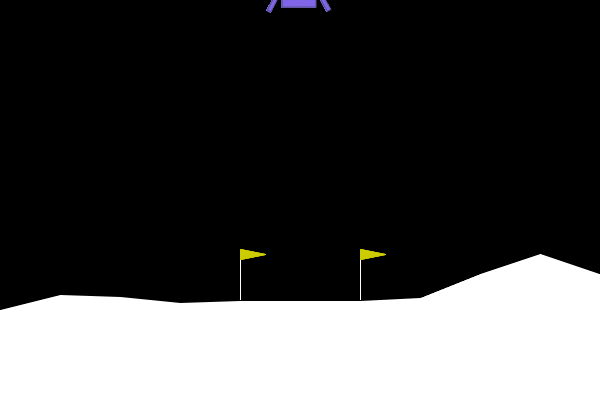

In [8]:
*_, ret, frames = run_lander(tabpfn, seed=1000, render=True)
print(f"return {ret:.0f}")
show_gif(frames[::2], "lunar_lander.gif", seconds_per_frame=0.04)

## Example 2: HalfCheetah

*TabPFN copies a pretrained TD3 policy and runs a MuJoCo robot with 6 joints.*

`HalfCheetah-v5` has a 17-value state (joint angles and velocities) and 6 joint torques. The reward is mostly forward speed. The expert is [`sb3/td3-HalfCheetah-v3`](https://huggingface.co/sb3/td3-HalfCheetah-v3), a TD3 policy from the Stable-Baselines3 model zoo.

*Make the environment and roll out with optional action noise.*

With `noise > 0`, the robot executes a perturbed action but we log the expert's clean action. The context then also shows how to recover from small mistakes.

For the GIF, the camera follows the robot (`camera_name="track"`). The default floor is 80 m long and the cheetah runs further, so we make the floor 50 times longer. MuJoCo prints a harmless deprecation warning about `settotalmass` each time it loads the model.

In [9]:
CHEETAH = "HalfCheetah-v5"


def make_cheetah(render=False):
    env = gym.make(CHEETAH, render_mode="rgb_array" if render else None, width=320, height=240, camera_name="track")
    model = env.unwrapped.model
    model.geom_size[0, :2] *= 50  # longer floor
    model.mat_texrepeat[model.geom_matid[0]] *= 50  # same tile size
    return env


def run_cheetah(env, policy, seed, steps=1000, noise=0.0):
    rng = np.random.default_rng(seed)
    obs, _ = env.reset(seed=seed)
    states, actions, frames, total = [], [], [], 0.0
    for t in range(steps):
        action = np.clip(policy(obs), -1, 1)
        states.append(obs)
        actions.append(action)
        if env.render_mode and t % 3 == 0:
            frames.append(env.render())
        obs, reward, *_ = env.step(np.clip(action + rng.normal(0, noise, action.shape), -1, 1))
        total += reward
    return np.array(states), np.array(actions), total, env.unwrapped.data.qpos[0], frames


cheetah_env = make_cheetah()

*Load the expert. It was saved with the old `gym` package, so we pass the spaces.*

In [10]:
from huggingface_sb3 import load_from_hub
from stable_baselines3 import TD3

td3 = TD3.load(
    load_from_hub("sb3/td3-HalfCheetah-v3", "td3-HalfCheetah-v3.zip"),
    device="cpu",
    custom_objects={
        "observation_space": cheetah_env.observation_space,
        "action_space": cheetah_env.action_space,
        "learning_rate": 0.0,
        "lr_schedule": lambda _: 0.0,
        "train_freq": 1,
    },
)
cheetah_expert = lambda obs: td3.predict(obs, deterministic=True)[0]

*Log noisy expert demonstrations and keep a random subset as the context.*

Each transition becomes 6 rows, one per joint.

In [11]:
DEMOS = 5  # expert episodes of 1,000 steps
CONTEXT = 4000  # transitions kept in the context

demos = [run_cheetah(cheetah_env, cheetah_expert, seed=s, noise=0.1) for s in range(DEMOS)]
x = np.concatenate([d[0] for d in demos])
y = np.concatenate([d[1] for d in demos])
keep = np.random.default_rng(0).choice(len(x), min(CONTEXT, len(x)), replace=False)

start = time.perf_counter()
cheetah_policy = PooledRegressor().fit(x[keep], y[keep])
print(f"context: {len(keep)} transitions x 6 joints = {6 * len(keep)} rows; fit {time.perf_counter() - start:.1f} s")

context: 4000 transitions x 6 joints = 24000 rows; fit 2.9 s


*Run TabPFN and the expert for 1,000 steps each, on new seeds.*

In [12]:
TESTS = 3
tabpfn = lambda obs: cheetah_policy.predict(obs)[0]

for name, policy in [("expert", cheetah_expert), ("tabpfn", tabpfn)]:
    start = time.perf_counter()
    runs = [run_cheetah(cheetah_env, policy, seed=1000 + s) for s in range(TESTS)]
    step_ms = (time.perf_counter() - start) / (TESTS * 1000) * 1000
    returns = [r[2] for r in runs]
    distance = np.mean([r[3] for r in runs])
    print(f"{name}: return {np.mean(returns):.0f} ± {np.std(returns):.0f} over {TESTS} runs, "
          f"distance {distance:.0f} m, control step {step_ms:.1f} ms")
print(f"tabpfn predict: {cheetah_policy.latency()}")

expert: return 9411 ± 90 over 3 runs, distance 495 m, control step 0.6 ms


tabpfn: return 9361 ± 84 over 3 runs, distance 492 m, control step 41.4 ms
tabpfn predict: median 40.9 ms, p90 42.1 ms over 2999 calls


*Watch TabPFN run for 300 steps (15 s of simulated time), shown in real time.*

return 2415, distance 128 m


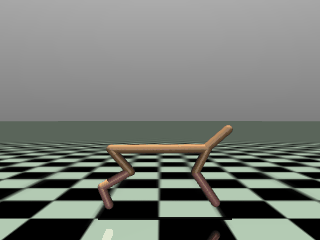

In [13]:
*_, ret, distance, frames = run_cheetah(make_cheetah(render=True), tabpfn, seed=1000, steps=300)
print(f"return {ret:.0f}, distance {distance:.0f} m")
show_gif(frames, "half_cheetah.gif", seconds_per_frame=0.15)  # 0.05 s per control step, every 3rd frame

## Results

On a T4 GPU with Python 3.12, the whole notebook ran in 409 s. The `pip install` took 146 s of that.

| | Lunar Lander | HalfCheetah |
|:--|:--|:--|
| Context | 2,029 transitions x 2 engines = 4,058 rows | 4,000 transitions x 6 joints = 24,000 rows |
| Predict call (median / p90) | 38.3 ms / 40.5 ms | 40.9 ms / 42.1 ms |
| TabPFN | mean return 257, 9 of 10 episodes solved | return 9,361 ± 84 over 3 runs |
| Expert | mean return 285, 10 of 10 episodes solved | return 9,411 ± 90 over 3 runs |

TabPFN gets close to both experts with no training. One predict call answers all joints in about 40 ms, which is less than HalfCheetah's 50 ms control step. The test sets are small (10 and 3 runs), so read the results as "TabPFN matches the expert", not as an exact ranking. Your numbers change with the GPU and the package versions.

## Run longer

The defaults keep the notebook short. To get tighter numbers or a harder test:

- Raise `TESTS` in either example. Each Lunar Lander episode adds a few hundred predict calls, and each HalfCheetah run adds 1,000.
- Change `DEMOS` and `CONTEXT` to see how much demonstration data TabPFN needs. Fewer rows make each call faster.
- Without a GPU, set `DEVICE = "cpu"`. Each call is then much slower.

## Next steps

- A planner that needs many predictions per control step should put them into one `predict` call, not one call each.
- Try a harder robot: Ant, Humanoid, or a model from [MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie).
- For a full walking robot at 50 Hz, see [duckpfn](https://github.com/nikikilbertus/duckpfn).